# Can the per-step regularisation be chosen without tuning?

**Problem.** At every step MGD solves $\hat G\,\theta = b$. When two statistics are near-copies, $\hat G$ is nearly singular
and the solution splits into two huge, opposite coefficients that cancel. The samples don't notice (they only feel the sum),
but $\theta$ itself becomes meaningless. Today's fix is a ridge $(\hat G + \lambda\,\mathrm{diag}\hat G)\theta = b$, and $\lambda$ must be tuned.

**Candidate without tuning (`ito_cg`).** Solve with conjugate gradients from $\theta=0$ and stop as soon as the remaining
mismatch is as small as the noise that the predictor's random kicks put into $b$. That noise level is not chosen: its
covariance is $2\hat G/(N h\sigma^2)$, known at every step. The only setting is the usual 5% confidence level.

**Test with known answer.** Gaussian in $d=8$, statistics $x_ix_j$ (36) plus near-copies $s(x_i)s(x_j)$ with
$s(u)=u+\delta u^3$ (36 more); $\delta$ = **perturbation strength** (not $\varepsilon$, which is the stopping threshold). The walkers stay exactly Gaussian, so the true $\theta$ is known at every step:
$C_t^{-1}$ on the originals, **0 on the copies**. $\delta=0.01$ is nearly singular (condition number $8.5\times10^4$),
$\delta=0.1$ less so ($10^3$). $N=10^4$ walkers, $\sigma^2=1$, 1000 steps, 5 seeds (same random numbers for every method
within a seed). Ridge: 9 values of $\lambda$ from $10^{-7}$ to $1$.

In [1]:
import glob
from pathlib import Path
import numpy as np, torch, matplotlib.pyplot as plt

RUNS = Path('results/gauss_d8_neardup/runs')
R = {}
for f in glob.glob(str(RUNS / '*.pt')):
    r = torch.load(f, weights_only=False)
    R[(r['eps'], r['method'], r['seed'])] = r
SEEDS = sorted({k[2] for k in R}); EPS = (0.01, 0.1)
RIDGE = {1e-7: 'ridge1e-7', 1e-4: 'ridge1e-4', 1e-3: 'ridge1e-3', 3e-3: 'ridge3e-3', 1e-2: 'ridge1e-2',
         3e-2: 'ridge3e-2', 1e-1: 'ridge1e-1', 3e-1: 'ridge3e-1', 1.0: 'ridge1'}
LAMS = list(RIDGE)
tavg = lambda key: (lambda r: r[key][r['t'] >= 0.05].mean())
METRIC = {   # name: (function of one run, axis label)
    'copies':  (tavg('psi_norm_pop'), 'size of θ on the copies\n(truth 0), relative to $C_t^{-1}$'),
    'entropy': (lambda r: r['S_int'] - r['S_exact_emp'], 'entropy estimate − exact\n(nats, truth 0)'),
    'KL':      (lambda r: r['KL_pop'], 'KL(samples ‖ target) at t = 1'),
}
def vals(eps, method, metric):
    return np.array([METRIC[metric][0](R[(eps, method, s)]) for s in SEEDS])
print(len(R), 'runs,', len(SEEDS), 'seeds')

150 runs, 5 seeds


## 1. Ridge as a function of λ, against `ito_cg`

Blue: ridge as a function of $\lambda$. Orange band: `ito_cg` (one point, no $\lambda$; band = mean ± standard error over seeds).
- **Top:** a larger $\lambda$ always shrinks the spurious copy coefficients, because it pulls all of $\theta$ towards 0.
  `ito_cg` reduces them 2.2–2.5× against the direct solve ($\lambda\to0$) without any $\lambda$.
- **Middle:** entropy estimate minus exact. **Caution: near-zero here is a cancellation, not correctness** (section 2).
- **Bottom:** the samples are unaffected unless $\lambda$ is very large.

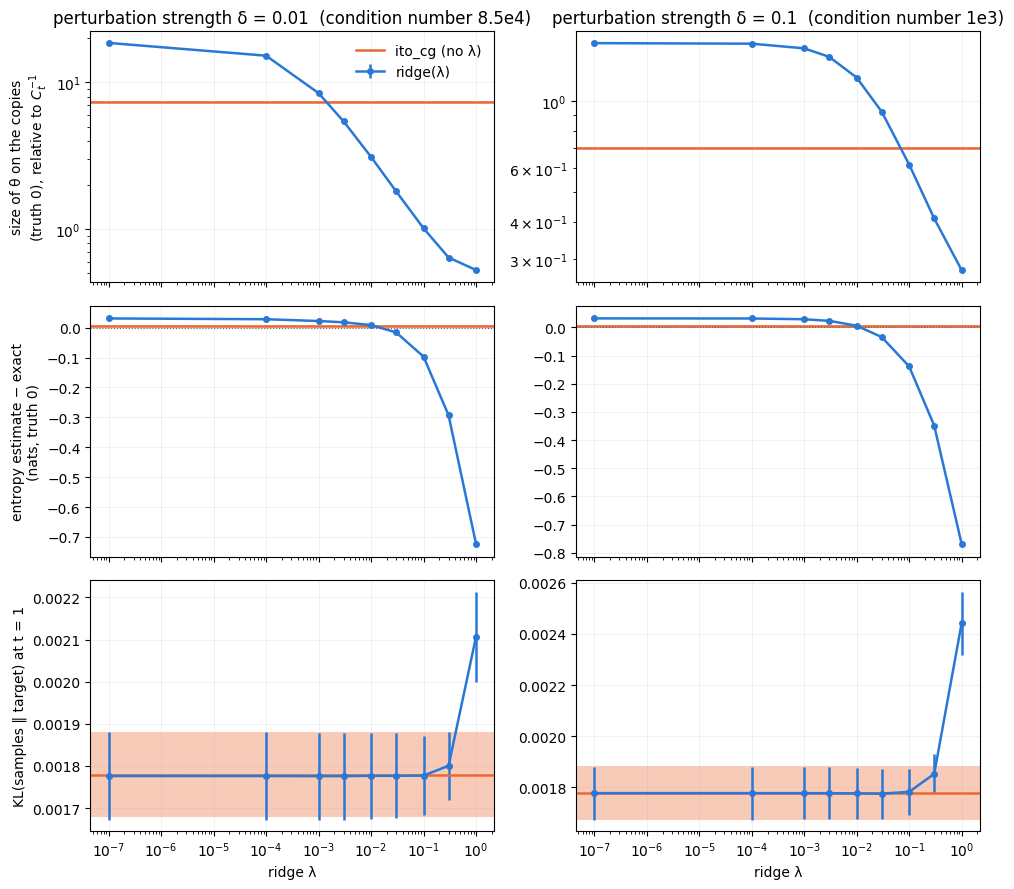

In [2]:
fig, ax = plt.subplots(3, 2, figsize=(10, 9), sharex=True)
for j, eps in enumerate(EPS):
    for i, metric in enumerate(METRIC):
        a = ax[i, j]
        y = np.array([vals(eps, RIDGE[l], metric) for l in LAMS])
        a.errorbar(LAMS, y.mean(1), y.std(1, ddof=1) / np.sqrt(len(SEEDS)), color='#2a78d6', marker='o', ms=4, lw=1.8, label='ridge(λ)')
        v = vals(eps, 'ito_cg', metric); m, se = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
        a.axhspan(m - se, m + se, color='#eb6834', alpha=0.35, lw=0)
        a.axhline(m, color='#eb6834', lw=1.8, label='ito_cg (no λ)')
        if metric == 'entropy':
            a.axhline(0, color='0.4', lw=0.8, ls=':')
        a.set_xscale('log'); a.grid(alpha=0.25, lw=0.5)
        if metric == 'copies': a.set_yscale('log')
        if j == 0: a.set_ylabel(METRIC[metric][1])
        if i == 0: a.set_title(f'perturbation strength δ = {eps}  (condition number {"8.5e4" if eps == 0.01 else "1e3"})')
    ax[-1, j].set_xlabel('ridge λ')
ax[0, 0].legend(frameon=False)
fig.tight_layout(); fig.savefig('results/gauss_d8_neardup/figures/fig1_ridge_vs_ito.png', dpi=150); plt.show()

## 2. Why the entropy panel cannot be used as evidence

The direct solve has a positive entropy bias even **without** duplicates (+0.020 nats in the duplicate-free run at the same
$N$, $\sigma^2$; the duplicates raise it to +0.031). Paired shifts against the direct solve:

| shift vs direct | no duplicates | δ = 0.01 | δ = 0.1 |
|---|---|---|---|
| ridge $10^{-2}$ | −0.025 | −0.022 | −0.026 |
| direct θ + early-stopped η | −0.004 | −0.024 | −0.025 |
| `ito_cg` (early-stopped θ and η) | +0.002 | −0.025 | −0.027 |
| early-stopped θ alone | +0.006 | −0.001 | −0.002 |

- Ridge shifts the bias by a fixed −0.025: its zero crossing is shrinkage cancelling the generic positive bias.
- `ito_cg`'s shift comes from the **η** stopping rule (the `ito_cg` method also early-stops η), and only with duplicates.
  Early-stopping θ itself barely changes the entropy. Without duplicates `ito_cg` has the direct solve's bias.

The table below is kept for reference (copies size, entropy, KL per method).

In [3]:
rows = []
for eps in EPS:
    for meth in ['direct'] + [RIDGE[l] for l in (1e-3, 1e-2, 3e-2, 1e-1, 1.0)] + ['ito_cg']:
        ent = vals(eps, meth, 'entropy'); d = np.abs(ent) - np.abs(vals(eps, 'ito_cg', 'entropy'))
        rows.append((eps, meth, vals(eps, meth, 'copies').mean(), ent.mean(), d.mean(), d.std(ddof=1) / np.sqrt(len(d)),
                     1e3 * vals(eps, meth, 'KL').mean()))
print(f"{'δ':>5} {'method':>11} {'copies':>8} {'entropy bias':>13} {'|bias|-|bias ito|':>20} {'KL x1e3':>8}")
for eps, meth, c, e, d, se, kl in rows:
    print(f'{eps:5g} {meth:>11} {c:8.2f} {e:+13.4f} {d:+12.4f} ± {se:.4f} {kl:8.3f}')

    δ      method   copies  entropy bias    |bias|-|bias ito|  KL x1e3
 0.01      direct    18.60       +0.0309      +0.0213 ± 0.0042    1.776
 0.01   ridge1e-3     8.45       +0.0222      +0.0127 ± 0.0043    1.776
 0.01   ridge1e-2     3.11       +0.0086      +0.0021 ± 0.0015    1.777
 0.01   ridge3e-2     1.81       -0.0158      +0.0062 ± 0.0048    1.777
 0.01   ridge1e-1     1.01       -0.0969      +0.0874 ± 0.0046    1.777
 0.01      ridge1     0.53       -0.7232      +0.7137 ± 0.0042    2.106
 0.01      ito_cg     7.41       +0.0055      +0.0000 ± 0.0000    1.779
  0.1      direct     1.56       +0.0320      +0.0221 ± 0.0045    1.776
  0.1   ridge1e-3     1.50       +0.0290      +0.0191 ± 0.0045    1.776
  0.1   ridge1e-2     1.20       +0.0059      +0.0001 ± 0.0009    1.775
  0.1   ridge3e-2     0.92       -0.0343      +0.0244 ± 0.0045    1.774
  0.1   ridge1e-1     0.62       -0.1385      +0.1287 ± 0.0040    1.781
  0.1      ridge1     0.28       -0.7689      +0.7590 ± 0.0040   

## 3. Over time: the copy coefficients along the run ($\delta=0.01$)

Seed-averaged size of $\theta$ on the copies (truth 0), smoothed over 20 steps. `ito_cg` stays well below the direct solve
throughout, between ridge $10^{-3}$ and $3\times10^{-3}$ in level; no method removes the copies.

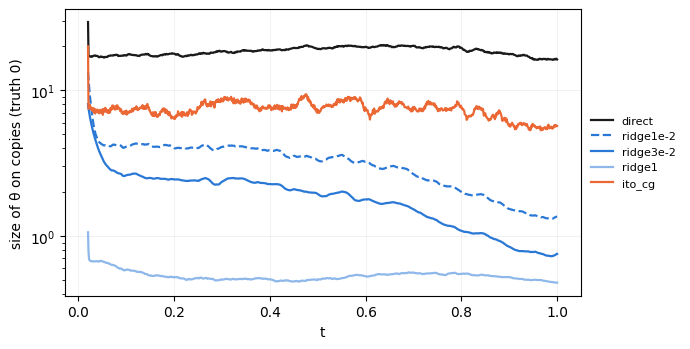

In [4]:
def smooth(x, w=20):
    c = np.cumsum(np.insert(x, 0, 0.0)); return (c[w:] - c[:-w]) / w
eps = 0.01
fig, a = plt.subplots(figsize=(7, 3.6))
for meth, col, ls in (('direct', '0.1', '-'), (RIDGE[1e-2], '#2a78d6', '--'), (RIDGE[3e-2], '#2a78d6', '-'),
                      (RIDGE[1.0], '#8fb8ea', '-'), ('ito_cg', '#eb6834', '-')):
    y = np.mean([R[(eps, meth, s)]['psi_norm_pop'] for s in SEEDS], 0)
    t = R[(eps, meth, SEEDS[0])]['t']
    a.plot(t[19:], smooth(y), color=col, ls=ls, lw=1.6, label=meth)
a.set_yscale('log'); a.set_xlabel('t'); a.set_ylabel('size of θ on copies (truth 0)'); a.grid(alpha=0.25, lw=0.5)
a.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
fig.tight_layout(); fig.savefig('results/gauss_d8_neardup/figures/fig3_copies_over_time.png', dpi=150, bbox_inches='tight'); plt.show()

## What this shows, and what it does not

- **Shown.** Without any tuning, early-stopped θ (`ito_cg`) reduces the spurious cancelling coefficients 2.2–2.5× against
  the direct solve and leaves the samples unchanged. Against ridge it is mixed: better than $\lambda=10^{-2}$ at $\delta=0.1$,
  worse at $\delta=0.01$. Fair summary: **comparable to a reasonable ridge, without choosing $\lambda$**.
- **Not shown.** That `ito_cg` gets θ right: its near-zero entropy bias is a cancellation (section 2), and it keeps a large split
  (7.4× the true θ at $\delta=0.01$). Its rule protects the moments, not θ: noise along near-singular directions is
  small in $b$, so the rule insists on fitting them, which is where θ noise is amplified.
- **Open.** A metric that tests θ without cancellations; a stopping rule aimed at θ accuracy; whether the best ridge $\lambda$
  moves between problems. On an exactly singular $\hat G$ the stopping statistic needs a pseudo-inverse (current code fails).